# Create Dataset

In [ ]:
!python -m pip freeze > requirements.txt

In [ ]:

!pip -q install kagglehub opencv-python-headless

import kagglehub
from pathlib import Path

DATASET_PATH = Path(
    kagglehub.dataset_download(
        "oshanyalegama/div2k-dataset"
    )
)

print("Dataset downloaded:", DATASET_PATH)

# สำรวจโครงสร้างโฟลเดอร์ HR
for p in sorted(DATASET_PATH.rglob("*")):
    if p.is_dir() and "hr" in p.name.lower():
        print(p)


In [ ]:
import random
import numpy as np
import cv2
import csv

from PIL import Image
from pathlib import Path
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

IMAGE_SIZE = 128
# ทุก split ตัดจำนวน patch เท่ากัน เพื่อให้สัดส่วนภาพตรง 70/10/20
PATCHES_TRAIN = 4
PATCHES_VALID = 4
PATCHES_TEST = 4

OUTPUT_DIR = Path("/kaggle/working//DIV2K_Restoration")

# ค้นหาเฉพาะภาพ HR เพื่อไม่ให้ปนภาพ LR
def find_hr_images(root, split):
    folder_name = f"div2k_{split}_hr"

    images = [
        p for p in root.rglob("*")
        if p.suffix.lower() in {".png", ".jpg", ".jpeg"}
        and any(
            part.lower() == folder_name
            for part in p.parts
        )
    ]

    return sorted(images)

original_train = find_hr_images(DATASET_PATH, "train")
original_valid = find_hr_images(DATASET_PATH, "valid")

print("Original Train:", len(original_train))
print("Original Valid:", len(original_valid))

assert len(original_train) > 0, (
    "ไม่พบ DIV2K_train_HR กรุณาตรวจโฟลเดอร์"
)
assert len(original_valid) > 0, (
    "ไม่พบ DIV2K_valid_HR กรุณาตรวจโฟลเดอร์"
)

# รวมภาพ HR ทั้งหมด (800 + 100 = 900) แล้วแบ่งที่ระดับภาพต้นฉบับ
# Train 70% / Valid 10% / Test 20%
all_files = original_train + original_valid

train_files, test_files = train_test_split(
    all_files,
    test_size=0.2,
    random_state=SEED,
    shuffle=True
)

# เหลือ 80% -> valid = 10% ของทั้งหมด = 1/8 ของส่วนที่เหลือ
train_files, valid_files = train_test_split(
    train_files,
    test_size=1 / 8,
    random_state=SEED,
    shuffle=True
)

splits = {
    "train": train_files,
    "valid": valid_files,
    "test": test_files
}

for split, files in splits.items():
    print(f"{split}: {len(files)} original images")


In [ ]:
def add_gaussian_noise(image, rng):
    sigma = rng.uniform(10, 30)

    noise = rng.normal(
        0, sigma, image.shape
    )

    noisy = image.astype(np.float32) + noise

    return np.clip(
        noisy, 0, 255
    ).astype(np.uint8), sigma


def add_gaussian_blur(image, rng):
    kernel_size = int(rng.choice([5, 7, 9, 11]))
    sigma = float(rng.uniform(1.0, 3.0))

    blurred = cv2.GaussianBlur(
        image,
        (kernel_size, kernel_size),
        sigmaX=sigma
    )

    return blurred, sigma


def create_degradations(clean, rng):
    # Noise อย่างเดียว
    noisy, noise_sigma = add_gaussian_noise(
        clean, rng
    )

    # Blur อย่างเดียว
    blurred, blur_sigma = add_gaussian_blur(
        clean, rng
    )

    # ทั้ง Noise + Blur
    combined, combined_noise_sigma = add_gaussian_noise(
        blurred, rng
    )

    return {
        "noise": noisy,
        "blur": blurred,
        "noise_blur": combined
    }, noise_sigma, blur_sigma, combined_noise_sigma


In [ ]:
import shutil

def random_crop(image, size, rng):
    h, w = image.shape[:2]

    if h < size or w < size:
        raise ValueError(
            f"Image is too small: {w}x{h}"
        )

    top = int(rng.integers(0, h - size + 1))
    left = int(rng.integers(0, w - size + 1))

    return image[
        top:top + size,
        left:left + size
    ]


def save_rgb(path, image):
    Image.fromarray(image).save(path)


def build_dataset():
    records = []

    for split, files in splits.items():
        patches = {
            "train": PATCHES_TRAIN,
            "valid": PATCHES_VALID,
            "test": PATCHES_TEST
        }[split]

        for category in [
            "clean", "noise", "blur", "noise_blur"
        ]:
            category_dir = OUTPUT_DIR / split / category

            # ล้างภาพจากรอบก่อน เพื่อไม่ให้ปนกับรอบใหม่
            if category_dir.exists():
                shutil.rmtree(category_dir)

            category_dir.mkdir(
                parents=True, exist_ok=True
            )

        print(f"\nProcessing {split}...")

        for idx, path in enumerate(files):
            with Image.open(path) as img:
                image = np.array(
                    img.convert("RGB")
                )

            # Seed คงที่ ทำซ้ำแล้วได้ภาพเดิม
            rng = np.random.default_rng(
                SEED + idx + {
                    "train": 0,
                    "valid": 100000,
                    "test": 200000
                }[split]
            )

            for patch_idx in range(patches):
                clean = random_crop(
                    image, IMAGE_SIZE, rng
                )

                (
                    degraded, noise_sigma, blur_sigma,
                    combined_noise_sigma
                ) = create_degradations(clean, rng)

                filename = (
                    f"{path.stem}_{patch_idx:03d}.png"
                )

                save_rgb(
                    OUTPUT_DIR / split / "clean" / filename,
                    clean
                )

                for category, result in degraded.items():
                    save_rgb(
                        OUTPUT_DIR / split / category / filename,
                        result
                    )

                records.append({
                    "split": split,
                    "source": path.name,
                    "filename": filename,
                    "noise_sigma": round(noise_sigma, 3),
                    "blur_sigma": round(blur_sigma, 3),
                    "combined_noise_sigma": round(combined_noise_sigma, 3)
                })

            if (idx + 1) % 50 == 0:
                print(f"  {idx + 1}/{len(files)} images")

    with open(
        OUTPUT_DIR / "manifest.csv",
        "w",
        newline=""
    ) as f:
        writer = csv.DictWriter(
            f,
            fieldnames=[
                "split", "source", "filename",
                "noise_sigma", "blur_sigma",
                "combined_noise_sigma"
            ]
        )
        writer.writeheader()
        writer.writerows(records)

    print("\nDataset created at:", OUTPUT_DIR)
    return records


records = build_dataset()


In [ ]:
import matplotlib.pyplot as plt

sample_path = sorted(
    (OUTPUT_DIR / "train" / "clean").glob("*.png")
)[0]

filename = sample_path.name

categories = [
    "clean",
    "noise",
    "blur",
    "noise_blur"
]

titles = [
    "Original",
    "Gaussian Noise",
    "Gaussian Blur",
    "Noise + Blur"
]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, category, title in zip(
    axes, categories, titles
):
    path = OUTPUT_DIR / "train" / category / filename

    img = Image.open(path)
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

# ตรวจ Data Leakage ระหว่าง Source Images
source_sets = {
    name: set(p.name for p in files)
    for name, files in splits.items()
}

assert not (
    source_sets["train"] & source_sets["valid"]
)
assert not (
    source_sets["train"] & source_sets["test"]
)
assert not (
    source_sets["valid"] & source_sets["test"]
)

# ตรวจจำนวนไฟล์แต่ละประเภท
for split in splits:
    counts = {
        category: len(list(
            (OUTPUT_DIR / split / category).glob("*.png")
        ))
        for category in [
            "clean", "noise", "blur", "noise_blur"
        ]
    }

    assert len(set(counts.values())) == 1, counts

    # ตรวจว่าชื่อไฟล์จับคู่กันครบ
    names = [
        {p.name for p in (
            OUTPUT_DIR / split / category
        ).glob("*.png")}
        for category in counts
    ]

    assert all(n == names[0] for n in names)

    print(split, counts)

print("Dataset split and pairing checks passed!")


In [ ]:

import shutil
from pathlib import Path
from IPython.display import FileLink, display

folder = Path("/kaggle/working/DIV2K_Restoration")

zip_path = shutil.make_archive(
    "/kaggle/working/DIV2K_Restoration",
    "zip",
    root_dir=folder.parent,
    base_dir=folder.name
)

print("ZIP created:", zip_path)
print("Size:", round(Path(zip_path).stat().st_size / 1024**2, 2), "MB")

display(FileLink(zip_path))


# Train: Conditional Diffusion
โมเดลรับ 3 อย่าง: ภาพสะอาดที่ถูกเติม diffusion noise (`x_t`), ภาพเสีย (`condition`) และ timestep (`t`)
แล้วทำนาย Gaussian noise ที่เติมในภาพสะอาด ใช้ MSE ระหว่าง noise จริงกับ noise ที่ทำนาย
ภาพเสียเป็นข้อมูลกำกับตลอดการเทรนและการสุ่มฟื้นฟู ไม่ใช่ target ของ forward diffusion

ใช้ DDPM noise-prediction objective และ DDIM sampling แบบ eta=0 เพื่อฟื้นฟูด้วย 50 รอบจาก 1,000 training timesteps
ค่าเริ่มต้นเป็น baseline ต้องเทรนและประเมินจริงก่อนสรุปคุณภาพ ภาพที่สร้างอาจเปลี่ยนรายละเอียดต้นฉบับ
Validation loss เป็น noise MSE ไม่ใช่ PSNR/SSIM ของภาพที่ฟื้นฟู

อ้างอิง: [Keras DDPM](https://keras.io/examples/generative/ddpm/),
[DDIM paper](https://arxiv.org/abs/2010.02502)

In [4]:
import json
import math
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from pathlib import Path
from tensorflow.keras import layers, Model

tf.keras.utils.set_random_seed(42)
SEED = 42
IMG_SIZE = 128
BATCH_SIZE = 8             # ลดเป็น 2 หรือ 4 หาก GPU memory ไม่พอ
EPOCHS = 30                # baseline; ไม่ใช่จำนวนที่รับประกันคุณภาพ
TIMESTEPS = 1000
SAMPLING_STEPS = 50
BASE_CHANNELS = 32
LEARNING_RATE = 2e-4
CATEGORIES = ['noise', 'blur', 'noise_blur']

# ใส่ path เองได้หากรันนอก Kaggle
DATA_DIR_OVERRIDE = "/kaggle/input/datasets/wisits/dataset1/DIV2K_Restoration"
MODEL_DIR = Path('/kaggle/working/diffusion_models') if Path('/kaggle').exists() else Path.cwd() / 'diffusion_models'
MODEL_DIR.mkdir(parents=True, exist_ok=True)

def resolve_data_dir():
    if DATA_DIR_OVERRIDE is not None:
        candidates = [Path(DATA_DIR_OVERRIDE)]
    else:
        candidates = [Path('/kaggle/working/DIV2K_Restoration'), Path.cwd() / 'DIV2K_Restoration']
        if Path('/kaggle/input').exists():
            candidates += sorted(Path('/kaggle/input').rglob('DIV2K_Restoration'))
    for path in candidates:
        if all((path / split / 'clean').is_dir() for split in ['train', 'valid', 'test']):
            return path
    raise FileNotFoundError('ไม่พบ DIV2K_Restoration ที่มี train/valid/test: รัน Create Dataset, Add Input หรือกำหนด DATA_DIR_OVERRIDE')

DATA_DIR = resolve_data_dir()
gpus = tf.config.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)
strategy = tf.distribute.MirroredStrategy()
print('Dataset:', DATA_DIR)
print('TensorFlow:', tf.__version__, '| GPUs:', gpus)
print('Replicas:', strategy.num_replicas_in_sync)
if not gpus:
    print('CPU ใช้ตรวจโค้ดได้ แต่แนะนำ GPU สำหรับเทรนจริง')

INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1')
Dataset: /kaggle/input/datasets/wisits/dataset1/DIV2K_Restoration
TensorFlow: 2.20.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Replicas: 2


In [5]:
def make_dataset(split, categories=None, shuffle=False):
    categories = CATEGORIES if categories is None else categories
    inputs, targets = [], []
    for category in categories:
        paths = sorted((DATA_DIR / split / category).glob('*.png'))
        if not paths:
            raise FileNotFoundError(DATA_DIR / split / category)
        for path in paths:
            target = DATA_DIR / split / 'clean' / path.name
            if not target.is_file():
                raise FileNotFoundError(target)
            inputs.append(str(path))
            targets.append(str(target))
    ds = tf.data.Dataset.from_tensor_slices((inputs, targets))
    if shuffle:
        ds = ds.shuffle(len(inputs), seed=SEED, reshuffle_each_iteration=True)

    def load_pair(input_path, target_path):
        def read(path):
            image = tf.io.decode_png(tf.io.read_file(path), channels=3)
            image = tf.image.convert_image_dtype(image, tf.float32)
            return tf.ensure_shape(image, [IMG_SIZE, IMG_SIZE, 3])
        return read(input_path), read(target_path)

    return ds.map(load_pair, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset('train', shuffle=True)
val_ds = make_dataset('valid')
for condition, clean in train_ds.take(1):
    print('Condition:', condition.shape, '| Clean:', clean.shape, '| range [0, 1]')

Condition: (8, 128, 128, 3) | Clean: (8, 128, 128, 3) | range [0, 1]


## Noise-prediction U-Net
ใช้ time embedding ส่ง timestep ไปยังทุกระดับของ U-Net และต่อภาพเสียกับ `x_t` ที่ช่องสี
Group Normalization เหมาะกับ batch ขนาดเล็ก Output เป็น noise จึงไม่มี sigmoid หรือการ clip ที่ชั้นสุดท้าย

In [6]:
@tf.keras.utils.register_keras_serializable(package='RestorationDiffusion')
class TimeEmbedding(layers.Layer):
    def __init__(self, dim, **kwargs):
        super().__init__(**kwargs)
        self.dim = dim

    def call(self, timesteps):
        half = self.dim // 2
        frequencies = tf.exp(-math.log(10000.0) * tf.range(half, dtype=tf.float32) / max(half - 1, 1))
        angles = tf.cast(timesteps[:, None], tf.float32) * frequencies[None, :]
        return tf.concat([tf.sin(angles), tf.cos(angles)], axis=-1)

    def get_config(self):
        return {**super().get_config(), 'dim': self.dim}

def residual_block(x, time_embedding, filters):
    shortcut = x
    if x.shape[-1] != filters:
        shortcut = layers.Conv2D(filters, 1, padding='same')(shortcut)
    h = layers.GroupNormalization(groups=8)(x)
    h = layers.Activation('swish')(h)
    h = layers.Conv2D(filters, 3, padding='same')(h)
    time_bias = layers.Dense(filters)(time_embedding)
    h = layers.Add()([h, layers.Reshape((1, 1, filters))(time_bias)])
    h = layers.GroupNormalization(groups=8)(h)
    h = layers.Activation('swish')(h)
    h = layers.Conv2D(filters, 3, padding='same')(h)
    return layers.Add()([shortcut, h])

def build_denoiser(image_size=IMG_SIZE, base_channels=BASE_CHANNELS):
    x_t = layers.Input((image_size, image_size, 3), name='x_t')
    condition = layers.Input((image_size, image_size, 3), name='condition')
    timestep = layers.Input((), dtype='int32', name='timestep')
    time = TimeEmbedding(base_channels)(timestep)
    time = layers.Dense(base_channels * 4, activation='swish')(time)
    time = layers.Dense(base_channels * 4, activation='swish')(time)
    h = layers.Concatenate()([x_t, condition])
    h = layers.Conv2D(base_channels, 3, padding='same')(h)
    skips = []
    for width in [base_channels, base_channels * 2, base_channels * 4]:
        h = residual_block(h, time, width)
        skips.append(h)
        h = layers.Conv2D(width, 3, strides=2, padding='same')(h)
    h = residual_block(h, time, base_channels * 8)
    for width, skip in zip([base_channels * 4, base_channels * 2, base_channels], reversed(skips)):
        h = layers.UpSampling2D(interpolation='nearest')(h)
        h = layers.Concatenate()([h, skip])
        h = residual_block(h, time, width)
    h = layers.GroupNormalization(groups=8)(h)
    h = layers.Activation('swish')(h)
    noise = layers.Conv2D(3, 3, padding='same', kernel_initializer='zeros', name='predicted_noise')(h)
    return Model([x_t, condition, timestep], noise, name='ConditionalDiffusionUNet')

In [7]:
def cosine_alpha_bars(timesteps):
    # cosine schedule ทำให้ปลาย forward process ใกล้ pure Gaussian noise
    grid = np.linspace(0, timesteps, timesteps + 1, dtype=np.float64) / timesteps
    cumulative = np.cos((grid + 0.008) / 1.008 * np.pi / 2) ** 2
    cumulative /= cumulative[0]
    betas = np.clip(1.0 - cumulative[1:] / cumulative[:-1], 1e-8, 0.999)
    return np.cumprod(1.0 - betas).astype('float32')

class ConditionalDiffusion(tf.keras.Model):
    def __init__(self, denoiser, timesteps=TIMESTEPS):
        super().__init__()
        self.denoiser = denoiser
        self.timesteps = timesteps
        self.alpha_bars = tf.constant(cosine_alpha_bars(timesteps))
        self.loss_tracker = tf.keras.metrics.Mean(name='loss')

    @property
    def metrics(self):
        return [self.loss_tracker]

    def call(self, inputs, training=False):
        return self.denoiser(inputs, training=training)

    def q_sample(self, clean, t, noise):
        alpha = tf.gather(self.alpha_bars, t)[:, None, None, None]
        return tf.sqrt(alpha) * clean + tf.sqrt(1.0 - alpha) * noise

    def train_step(self, data):
        condition, clean = data
        condition, clean = condition * 2.0 - 1.0, clean * 2.0 - 1.0
        count = tf.shape(clean)[0]
        t = tf.random.uniform([count], 0, self.timesteps, dtype=tf.int32)
        noise = tf.random.normal(tf.shape(clean))
        x_t = self.q_sample(clean, t, noise)
        # นับ global batch จริง รวม last batch ที่มีขนาดเล็กกว่า BATCH_SIZE
        context = tf.distribute.get_replica_context()
        global_count = context.all_reduce(tf.distribute.ReduceOp.SUM, count) if context else count
        with tf.GradientTape() as tape:
            predicted = self([x_t, condition, t], training=True)
            per_image_loss = tf.reduce_mean(tf.square(noise - predicted), axis=[1, 2, 3])
            loss = tf.nn.compute_average_loss(per_image_loss, global_batch_size=global_count)
        gradients = tape.gradient(loss, self.denoiser.trainable_variables)
        self.optimizer.apply_gradients(zip(gradients, self.denoiser.trainable_variables))
        self.loss_tracker.update_state(per_image_loss)
        return {'loss': self.loss_tracker.result()}

    def test_step(self, data):
        condition, clean = data
        condition, clean = condition * 2.0 - 1.0, clean * 2.0 - 1.0
        # fixed draws ต่อ batch ทำให้ val_loss เปรียบเทียบข้าม epoch ได้
        # ใช้ pattern เดิมซ้ำทุก batch; metric นี้ไม่ใช่ restoration quality
        t = tf.random.stateless_uniform([tf.shape(clean)[0]], [SEED, 10], 0, self.timesteps, dtype=tf.int32)
        noise = tf.random.stateless_normal(tf.shape(clean), [SEED, 11])
        predicted = self([self.q_sample(clean, t, noise), condition, t], training=False)
        per_image_loss = tf.reduce_mean(tf.square(noise - predicted), axis=[1, 2, 3])
        self.loss_tracker.update_state(per_image_loss)
        return {'loss': self.loss_tracker.result()}

with strategy.scope():
    denoiser = build_denoiser()
    model = ConditionalDiffusion(denoiser)
    # Build ด้วย inputs ทั้ง 3 ก่อน fit เพื่อไม่ให้ Keras ลอง build จาก condition เพียงตัวเดียว
    dummy = tf.zeros([1, IMG_SIZE, IMG_SIZE, 3])
    model([dummy, dummy, tf.zeros([1], dtype=tf.int32)], training=False)
    model.compile(optimizer=tf.keras.optimizers.Adam(LEARNING_RATE, global_clipnorm=1.0))
denoiser.summary()
print('Final alpha_bar:', float(model.alpha_bars[-1]))

Model: "ConditionalDiffusionUNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ x_t (InputLayer)    │ (None, 128, 128,  │          0 │ -                 │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ condition           │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ timestep            │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 128, 128,  │          0 │ x_t[0][0],        │
│ (Concatenate)       │ 6)                │            │ condition[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_embedding      │ (None, 32)        │          0 │ timestep[0][0]    │
│ (TimeEmbedding)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │      1,760 │ concatenate[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │      4,224 │ time_embedding[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalization │ (None, 128, 128,  │         64 │ conv2d[0][0]      │
│ (GroupNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │     16,512 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 128, 128,  │          0 │ group_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 32)        │      4,128 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │      9,248 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 1, 32)  │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 128, 128,  │          0 │ conv2d_1[0][0],   │
│                     │ 32)               │            │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalizatio… │ (None, 128, 128,  │         64 │ add[0][0]         │
│ (GroupNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 128, 128,  │          0 │ group_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │      9,248 │ activation_1[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 128, 128,  │          0 │ conv2d[0][0],     │
│                     │ 32)               │            │ conv2d_2[0][0]  

 Total params: 2,374,659 (9.06 MB)

 Trainable params: 2,374,659 (9.06 MB)

 Non-trainable params: 0 (0.00 B)

Final alpha_bar: 2.428766965323348e-09


In [ ]:
checkpoint_path = MODEL_DIR / 'best_diffusion.weights.h5'

class SaveBestDenoiser(tf.keras.callbacks.Callback):
    def __init__(self, path):
        super().__init__()
        self.path = str(path)
        self.best = float('inf')

    def on_epoch_end(self, epoch, logs=None):
        value = (logs or {}).get('val_loss')
        if value is not None and np.isfinite(value) and value < self.best:
            self.best = float(value)
            self.model.denoiser.save_weights(self.path)
            print(f' Saved best noise-prediction weights: val_loss={value:.6f}')

best_callback = SaveBestDenoiser(checkpoint_path)
callbacks = [
    best_callback,
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=8),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6),
    tf.keras.callbacks.CSVLogger(str(MODEL_DIR / 'training_log.csv')),
    tf.keras.callbacks.TerminateOnNaN(),
]
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks)
if not np.isfinite(best_callback.best) or not checkpoint_path.is_file():
    raise RuntimeError('ไม่มี checkpoint ที่มี finite val_loss: ตรวจ training log ก่อนประเมิน')

In [9]:
pathmodel = "/kaggle/input/models/wisits/ez/keras/default/1/best_diffusion.weights.h5"
denoiser.load_weights(pathmodel)
denoiser.save(MODEL_DIR / 'conditional_denoiser.keras')
config = {
    'timesteps': TIMESTEPS, 'sampling_steps': SAMPLING_STEPS,
    'schedule': 'cosine_s_0.008_beta_clip_0.999', 'image_size': IMG_SIZE,
    'base_channels': BASE_CHANNELS, 'categories': CATEGORIES,
    'normalization': 'images [0,1] -> denoiser [-1,1]',
    'seed': SEED, 'sampler': 'DDIM eta=0',
}
(MODEL_DIR / 'diffusion_config.json').write_text(json.dumps(config, indent=2), encoding='utf-8')
print('Best denoiser and config saved:', MODEL_DIR)

Best denoiser and config saved: /kaggle/working/diffusion_models


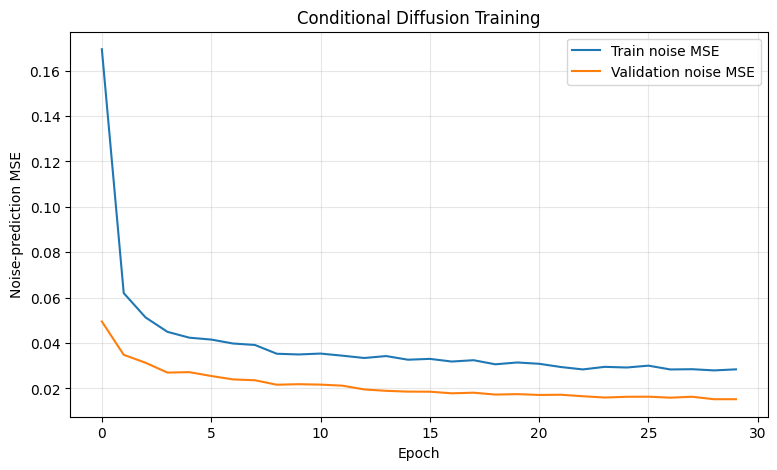

In [12]:
plt.figure(figsize=(9, 5))
plt.plot(history.history['loss'], label='Train noise MSE')
plt.plot(history.history['val_loss'], label='Validation noise MSE')
plt.xlabel('Epoch')
plt.ylabel('Noise-prediction MSE')
plt.title('Conditional Diffusion Training')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [10]:
import json
import numpy as np
import tensorflow as tf

# ต้องนิยาม TimeEmbedding และ cosine_alpha_bars ไว้แล้ว
gpus = tf.config.list_physical_devices("GPU")

if len(gpus) < 2:
    raise RuntimeError(
        f"พบ GPU {len(gpus)} ตัว กรุณาเปิด GPU 2 ตัวใน Kaggle"
    )

# ใช้ strategy เดิมหากมี GPU สองตัวอยู่แล้ว
if (
    "strategy" not in globals()
    or strategy.num_replicas_in_sync != 2
):
    strategy = tf.distribute.MirroredStrategy(
        devices=["/GPU:0", "/GPU:1"]
    )

# โหลดโมเดลภายใต้ strategy เพื่อวาง weights บน GPU ทั้งสอง
with strategy.scope():
    inference_denoiser = tf.keras.models.load_model(
        MODEL_DIR / "conditional_denoiser.keras",
        compile=False,
    )

saved_config = json.loads(
    (MODEL_DIR / "diffusion_config.json").read_text(
        encoding="utf-8"
    )
)

inference_alpha_bars = tf.constant(
    cosine_alpha_bars(saved_config["timesteps"]),
    dtype=tf.float32,
)

image_size = int(saved_config["image_size"])


def predict_on_replica(x, condition, timestep):
    context = tf.distribute.get_replica_context()
    replica_id = tf.cast(
        context.replica_id_in_sync_group,
        tf.int32,
    )

    local_batch = tf.shape(x)[0] // 2
    start = replica_id * local_batch
    end = start + local_batch

    return inference_denoiser(
        [
            x[start:end],
            condition[start:end],
            timestep[start:end],
        ],
        training=False,
    )


# Compile เฉพาะการทำนายหนึ่งรอบ ไม่มีลูป sampling ในกราฟ
@tf.function(
    input_signature=[
        tf.TensorSpec(
            [None, image_size, image_size, 3],
            tf.float32,
        ),
        tf.TensorSpec(
            [None, image_size, image_size, 3],
            tf.float32,
        ),
        tf.TensorSpec([None], tf.int32),
    ]
)
def predict_noise_two_gpus(x, condition, timestep):
    original_batch = tf.shape(x)[0]

    # เพิ่มภาพสำเนาหนึ่งภาพเมื่อ batch เป็นเลขคี่
    padding = original_batch % 2

    x = tf.concat(
        [x, x[:padding]], axis=0
    )
    condition = tf.concat(
        [condition, condition[:padding]], axis=0
    )
    timestep = tf.concat(
        [timestep, timestep[:padding]], axis=0
    )

    distributed_prediction = strategy.run(
        predict_on_replica,
        args=(x, condition, timestep),
    )

    prediction = strategy.gather(
        distributed_prediction,
        axis=0,
    )

    return prediction[:original_batch]


# ไม่ใส่ @tf.function ที่ restore:
# เก็บลูป sampling เป็น Python เพื่อหลีกเลี่ยงกราฟ while เดิม
def restore(
    denoiser,
    degraded,
    alpha_bars,
    sampling_steps=SAMPLING_STEPS,
    seed=SEED,
):
    if denoiser is not inference_denoiser:
        raise ValueError(
            "ต้องใช้ inference_denoiser ที่โหลดใน cell นี้"
        )

    sampling_steps = int(sampling_steps)

    alpha_bars = tf.convert_to_tensor(
        alpha_bars,
        dtype=tf.float32,
    )
    total_steps = int(alpha_bars.shape[0])

    if not 1 <= sampling_steps <= total_steps:
        raise ValueError(
            f"sampling_steps ต้องอยู่ระหว่าง 1 ถึง {total_steps}"
        )

    # degraded ต้องอยู่ช่วง [0, 1]
    condition = (
        tf.cast(degraded, tf.float32) * 2.0 - 1.0
    )

    x = tf.random.stateless_normal(
        tf.shape(condition),
        seed=[int(seed), 0],
        dtype=tf.float32,
    )

    times = np.linspace(
        total_steps - 1,
        0,
        sampling_steps,
    ).astype(np.int32)

    for i, t in enumerate(times):
        alpha = alpha_bars[int(t)]

        if i + 1 < len(times):
            previous_alpha = alpha_bars[
                int(times[i + 1])
            ]
        else:
            previous_alpha = tf.constant(
                1.0, dtype=tf.float32
            )

        batch_t = tf.fill(
            [tf.shape(x)[0]],
            tf.constant(int(t), dtype=tf.int32),
        )

        predicted_noise = predict_noise_two_gpus(
            x,
            condition,
            batch_t,
        )

        predicted_clean = (
            x
            - tf.sqrt(1.0 - alpha) * predicted_noise
        ) / tf.sqrt(alpha)

        predicted_clean = tf.clip_by_value(
            predicted_clean,
            -1.0,
            1.0,
        )

        consistent_noise = (
            x - tf.sqrt(alpha) * predicted_clean
        ) / tf.sqrt(1.0 - alpha)

        x = (
            tf.sqrt(previous_alpha) * predicted_clean
            + tf.sqrt(1.0 - previous_alpha)
            * consistent_noise
        )

    return tf.clip_by_value(
        (x + 1.0) / 2.0,
        0.0,
        1.0,
    )


print("GPU devices:", gpus[:2])
print("Replicas:", strategy.num_replicas_in_sync)
print("พร้อมใช้ restore() และ cell test เดิม")


GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Replicas: 2
พร้อมใช้ restore() และ cell test เดิม


In [16]:
results = {}

for category in CATEGORIES:
    ds = make_dataset(
        "test",
        categories=[category]
    )

    mae_scores = []
    mse_scores = []
    psnr_scores = []
    ssim_scores = []

    print(f"Evaluating: {category}", flush=True)

    for batch_index, (x, y) in enumerate(ds):
        # สร้างภาพที่ซ่อมแล้วผ่าน diffusion sampling
        pred = restore(
            inference_denoiser,
            x,
            inference_alpha_bars,
            sampling_steps=saved_config["sampling_steps"],
            seed=SEED + batch_index,
        )

        # y และ pred อยู่ในช่วง 0–1
        # คำนวณหนึ่งค่าต่อภาพ
        error = y - pred

        mae = tf.reduce_mean(
            tf.abs(error),
            axis=[1, 2, 3]
        )
        mse = tf.reduce_mean(
            tf.square(error),
            axis=[1, 2, 3]
        )

        psnr = tf.image.psnr(
            y,
            pred,
            max_val=1.0
        )
        ssim = tf.image.ssim(
            y,
            pred,
            max_val=1.0
        )

        mae_scores.extend(mae.numpy())
        mse_scores.extend(mse.numpy())
        psnr_scores.extend(psnr.numpy())
        ssim_scores.extend(ssim.numpy())

    # เฉลี่ยรายภาพทั้งชุดของแต่ละประเภท
    results[category] = {
        "MAE": float(np.mean(mae_scores)),
        "MSE": float(np.mean(mse_scores)),
        "PSNR": float(np.mean(psnr_scores)),
        "SSIM": float(np.mean(ssim_scores))
    }

    scores = results[category]

    print(
        f"{category:12s} | "
        f"MAE: {scores['MAE']:.6f} | "
        f"MSE: {scores['MSE']:.6f} | "
        f"PSNR: {scores['PSNR']:.2f} dB | "
        f"SSIM: {scores['SSIM']:.4f}",
        flush=True
    )


Evaluating: noise
INFO:tensorflow:Collective batch_all_gather: 1 all-gathers, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, 
noise        | MAE: 0.167916 | MSE: 0.048010 | PSNR: 15.59 dB | SSIM: 0.5664
Evaluating: blur
blur         | MAE: 0.177343 | MSE: 0.052735 | PSNR: 14.90 dB | SSIM: 0.4950
Evaluating: noise_blur
noise_blur   | MAE: 0.179519 | MSE: 0.053338 | PSNR: 14.68 dB | SSIM: 0.4375


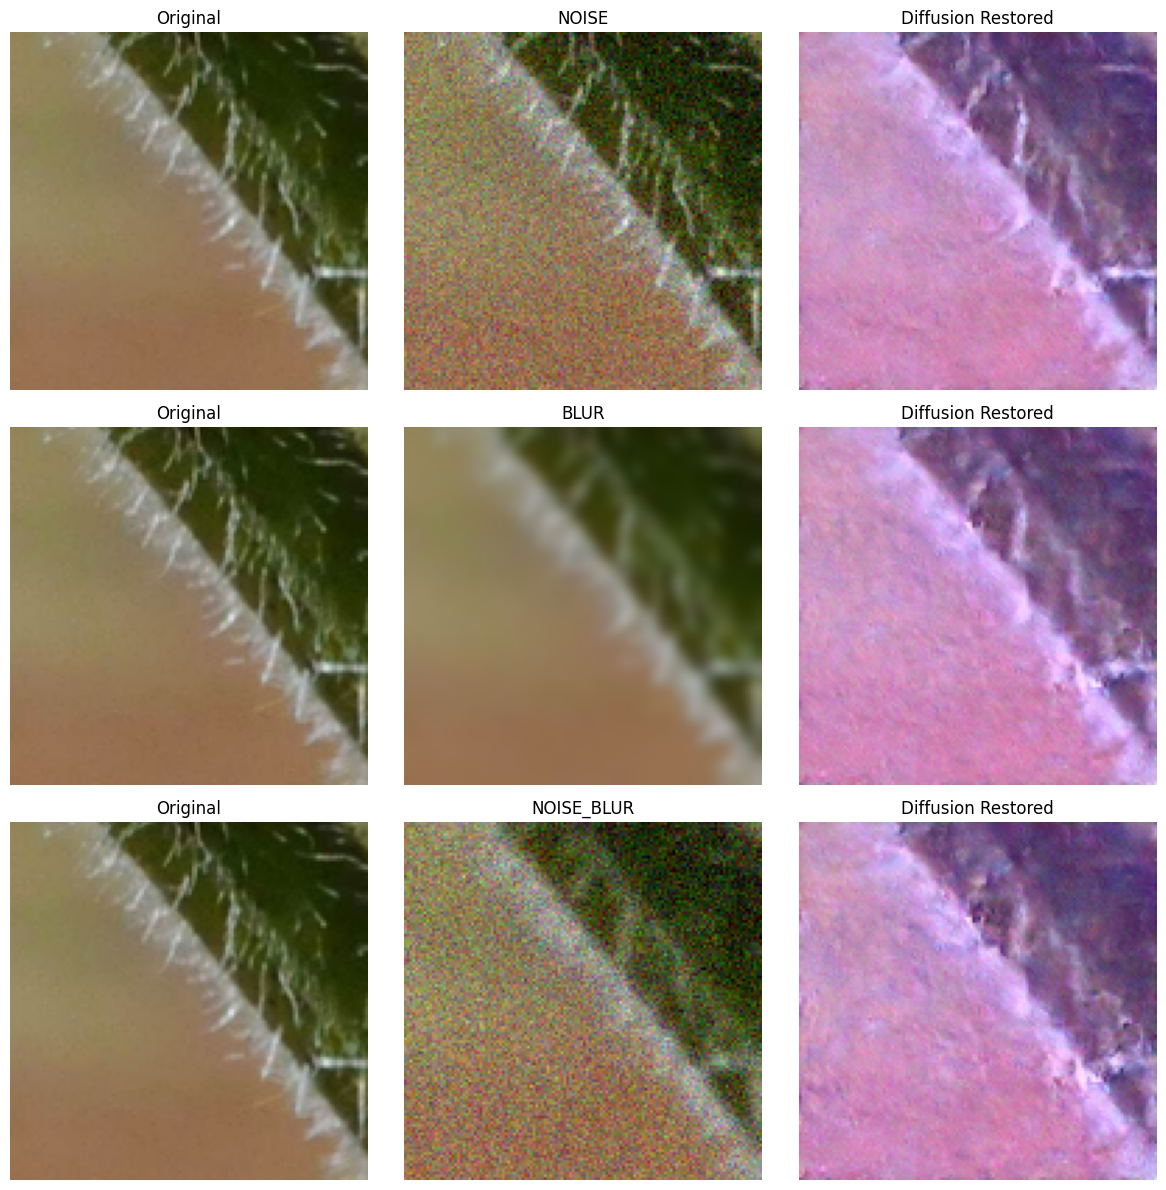

In [17]:
fig, axes = plt.subplots(3, 3, figsize=(12, 12))
for row, category in enumerate(CATEGORIES):
    degraded, clean = next(iter(make_dataset('test', categories=[category])))
    # ใช้ batch และ seed เดียวกับ batch แรกในการประเมิน
    prediction = restore(inference_denoiser, degraded, inference_alpha_bars,
                         sampling_steps=saved_config['sampling_steps'], seed=SEED)
    for col, (image, title) in enumerate(zip(
        [clean[0], degraded[0], prediction[0]], ['Original', category.upper(), 'Diffusion Restored']
    )):
        axes[row, col].imshow(image.numpy())
        axes[row, col].set_title(title)
        axes[row, col].axis('off')
plt.tight_layout()
plt.savefig(MODEL_DIR / 'diffusion_restoration_results.png', dpi=200)
plt.show()